# 2. Pretraining, training and niches

This vignette runs the default GRASS-MIL path on the tiles of vignette 1:

1. label-free pretraining of the ego-graph encoder (BGRL);
2. fine-tuning with the default regime (`finetune`), on one image for training,
   one for validation and one for testing;
3. per-cell outputs of the trained model;
4. niche discovery: which neighbourhoods the model relies on, and how they look.

Everything runs on a CPU; the step counts are small to keep it to a few minutes.

In [1]:
import json
import pathlib
import subprocess

import pandas as pd
from IPython.display import Image, Markdown, display

WORK = pathlib.Path("vignette_work").resolve()
DATA = WORK / "data"
COHORT = json.loads((WORK / "cohort.json").read_text())  # written by vignette 1

# Fine-tuning on a handful of tiles: a stronger probe penalty (the default C=1
# suits tens of thousands of ego-graphs) and more optimizer steps per epoch.
SMALL_DATA = ["finetune.probe.C=0.01", "finetune.hyperbatch_size=4"]


def run(command, *overrides):
    """Run a grass-mil command; show the end of its log if it fails.

    Commands that read the cohort (train, nested-cv, extract) get its settings;
    the analysis commands read a cell cache instead.
    """
    cohort = (
        COHORT["overrides"]
        if command in ("grass-mil-train", "grass-mil-nested-cv", "grass-mil-extract")
        else []
    )
    result = subprocess.run([command, *cohort, *overrides], capture_output=True, text=True)
    if result.returncode:
        print(result.stderr[-4000:])
        raise RuntimeError(f"{command} failed")

## 1. Pretraining

`regime=pretrain` trains the encoder on the ego-graphs of every cell, without
labels: two augmented views of each ego-graph should embed alike. A real cohort
uses the default 200,000 steps; 3,000 are enough here (a few minutes on a GPU,
about ten on a CPU). Too short a pretraining leaves the embeddings nearly
constant, and the probe head fitted on them in the next step then starts from
very large logits.

In [2]:
import torch

run(
    "grass-mil-train",
    "regime=pretrain",
    "pretrain.total_steps=3000",
    "pretrain.warmup_steps=100",
    "callbacks.model_checkpoint.every_n_train_steps=1000",
    "trainer=gpu" if torch.cuda.is_available() else "trainer=cpu",
    f"hydra.run.dir={WORK / 'pretrain'}",
)
ENCODER = WORK / "pretrain" / "checkpoints" / "last.ckpt"
print(ENCODER.relative_to(WORK.parent))

vignette_work/pretrain/checkpoints/last.ckpt


## 2. Fine-tuning

The default regime fine-tunes the pretrained encoder end to end. The linear
instance head is first fitted as a logistic probe on the frozen embeddings, and
the attention learns which cells of a tile to weight. Each image is one split.
With 16 training tiles, `SMALL_DATA` regularises the probe more strongly and
takes an optimizer step every 4 tiles instead of 12.

In [3]:
train_image, val_image, test_image = sorted(pd.read_csv(DATA / "labels.csv")["image"].unique())
run(
    "grass-mil-train",
    f"model.init_from_ckpt={ENCODER}",
    *SMALL_DATA,
    f"data.split.train=[{train_image}]",
    f"data.split.val=[{val_image}]",
    f"data.split.test=[{test_image}]",
    "trainer.max_epochs=20",
    "trainer.min_epochs=5",
    f"hydra.run.dir={WORK / 'train'}",
)
metrics = pd.read_json(WORK / "train" / "metrics_per_epoch.jsonl", lines=True)
display(metrics[["epoch", "train/loss_epoch", "val/loss", "val/auroc"]].round(3).tail())
pd.read_csv(WORK / "train" / "test_predictions.csv").round(3).head()

,epoch,train/loss_epoch,val/loss,val/auroc
15,15,0.148,2.893,0.886
16,16,0.190,2.788,0.914
17,17,0.128,2.541,0.914
18,18,0.120,2.491,0.914
19,19,0.105,2.483,0.914


,unit_id,prob_0,prob_1,pred,label,region_id,sample_id,patient_id
0,point8_tile000,0.776,0.224,0,0,point8,point8,point8
1,point8_tile001,0.994,0.006,0,0,point8,point8,point8
2,point8_tile002,0.908,0.092,0,0,point8,point8,point8
3,point8_tile003,0.732,0.268,0,0,point8,point8,point8
4,point8_tile004,0.743,0.257,0,0,point8,point8,point8


## 3. Per-cell outputs

`grass-mil-extract` rebuilds the model from its checkpoint and scores every cell
of every tile: its embedding, its coordinates in the attention head's space,
its instance logits and attention scores.

In [4]:
MODEL = WORK / "train" / "checkpoints" / "last.ckpt"
run(
    "grass-mil-extract",
    f"+extract.models.trained={MODEL}",
    f"extract.output_dir={WORK / 'cells'}",
    f"hydra.run.dir={WORK / 'extract'}",
)

## 4. Niches

`grass-mil-niches` clusters the cells in the model's attention space (cosine
HDBSCAN), numbers the niches by their attention-weighted margin (Niche 1 pushes
the prediction most towards *infiltrated*), and describes each by its
composition, its empirical association (the fraction of its cells from
infiltrated tiles) and the spatial arrangement of its cells. This model saw
every image during training or validation, so all tiles are analysed
(`units=all`); vignette 3 analyses held-out tiles of cross-validation models.
With only 3,300 cells, HDBSCAN's default cluster selection merges almost all
cells into one niche; `clustering.selection=leaf` keeps the finest stable
clusters.

In [5]:
run(
    "grass-mil-niches",
    f"cells_dir={WORK / 'cells' / 'trained'}",
    "units=all",
    "clustering.min_cluster_size=50",
    "clustering.selection=leaf",
    "positive_name=infiltrated",
    f"hydra.run.dir={WORK / 'niches'}",
)
NICHES = WORK / "niches"
display(Markdown((NICHES / "report.md").read_text()))

# Niches of trained

44 units, 3280 cells. Clustering: hdbscan in the attention space (PCA none, cosine True, fitted on 3280 cells, 15-NN assignment): 18 niches. Fraction of cells from infiltrated units: 0.539.

| Niche | Cells | Units (>2%) | Composition | Enriched (>1.5x) | Association | Margin [95% CI] | Sign consistency |
|---|---|---|---|---|---|---|---|
| Niche 1 | 7.1% | 10 | Tcell_CD4 39%, Imm_other 23%, Tcell_CD8 20% | Tcell_CD4 x1.6, Imm_other x1.6, Myeloid_CD11c x1.5 | 0.87 | +10.98 [+10.84, +11.42] | 1.00 |
| Niche 2 | 1.6% | 6 | Tcell_CD4 37%, Imm_other 19%, Tcell_CD8 17% | Myeloid_CD11c x2.2, Tcell_CD4 x1.5 | 0.80 | +9.32 [+7.53, +9.62] | 1.00 |
| Niche 3 | 2.3% | 7 | Tcell_CD4 39%, Imm_other 28%, Myeloid_CD11c 11% | Myeloid_CD11c x2.1, Imm_other x1.9, Tcell_CD4 x1.6 | 0.68 | +6.85 [+5.46, +7.15] | 1.00 |
| Niche 4 | 5.1% | 13 | Tcell_CD4 45%, Epithelial 20%, Imm_other 10% | Tcell_CD4 x1.9, Myeloid_CD11c x1.7 | 0.49 | +6.38 [+4.50, +7.02] | 1.00 |
| Niche 5 | 2.4% | 8 | Imm_other 35%, Tcell_CD4 20%, Endothelial 12% | Endothelial x3.6, Imm_other x2.4 | 0.62 | +3.00 [+2.09, +3.53] | 1.00 |
| Niche 6 | 1.6% | 6 | Tcell_CD8 34%, Tcell_CD4 26%, Imm_other 15% | Endothelial x2.7, Tcell_CD8 x2.4, Myeloid_CD11c x1.9 | 0.74 | +1.62 [-0.15, +3.28] | 0.62 |
| Niche 7 | 3.3% | 7 | Tcell_CD4 26%, Tcell_CD8 21%, Epithelial 19% | Myeloid_CD11c x2.0, Endothelial x1.6, Tcell_CD8 x1.5 | 0.46 | +0.92 [-1.00, +1.39] | 0.69 |
| Niche 8 | 4.2% | 13 | Tcell_CD4 21%, Tcell_CD8 17%, Fibroblast 15% | Myeloid_CD68 x1.9, Fibroblast x1.8 | 0.74 | -0.17 [-1.00, +1.79] | 0.53 |
| Niche 9 | 2.0% | 6 | Tcell_CD4 37%, Tcell_CD8 31%, Imm_other 13% | Tcell_CD8 x2.2, Endothelial x2.1, Tcell_CD4 x1.5 | 0.91 | -0.81 [-0.84, -0.72] | 0.86 |
| Niche 10 | 2.6% | 10 | Tcell_CD4 28%, Tcell_CD8 23%, Imm_other 17% | Tcell_CD8 x1.6 | 0.74 | -1.63 [-2.74, -0.88] | 0.92 |
| Niche 11 | 2.4% | 6 | Tcell_CD4 28%, Tcell_CD8 24%, Fibroblast 23% | Fibroblast x2.8, Tcell_CD8 x1.7 | 0.87 | -2.45 [-3.04, -1.86] | 1.00 |
| Niche 12 | 1.9% | 4 | Epithelial 89%, Endothelial 3%, Myeloid_CD68 3% | Epithelial x4.0 | 0.05 | -3.59 [-4.71, -0.21] | 1.00 |
| Niche 13 | 1.6% | 3 | Epithelial 77%, Fibroblast 6%, Tcell_CD4 6% | Epithelial x3.5 | 0.00 | -3.92 [-5.60, -2.88] | 1.00 |
| Niche 14 | 1.7% | 6 | Fibroblast 30%, Myeloid_CD68 25%, Imm_other 14% | Fibroblast x3.7, Myeloid_CD68 x3.2 | 0.16 | -4.04 [-4.77, -2.83] | 1.00 |
| Niche 15 | 1.5% | 4 | Epithelial 80%, Endothelial 8%, Imm_other 6% | Epithelial x3.6, Endothelial x2.3 | 0.00 | -4.34 [, ] | 1.00 |
| Niche 16 | 2.7% | 4 | Epithelial 44%, Myeloid_CD68 17%, Imm_other 14% | Endothelial x2.2, Myeloid_CD68 x2.1, Epithelial x2.0 | 0.04 | -4.76 [-4.99, -4.65] | 1.00 |
| Niche 17 | 2.0% | 6 | Myeloid_CD68 28%, Epithelial 22%, Fibroblast 21% | Myeloid_CD68 x3.6, Fibroblast x2.5 | 0.58 | -5.03 [-5.57, -3.77] | 1.00 |
| Niche 18 | 4.3% | 11 | Fibroblast 31%, Epithelial 26%, Imm_other 15% | Fibroblast x3.8 | 0.06 | -5.17 [-5.42, -4.83] | 1.00 |
| Background | 49.4% | 44 | Epithelial 24%, Tcell_CD4 24%, Imm_other 15% |  | 0.55 | -0.08 [-3.24, +5.88] | 0.50 |

## Clustered cell types within niches (Moran's I, q < 0.05)

- Niche 4: Epithelial I = 0.64 ± 0.03 (2 units)
- Niche 7: Epithelial I = 0.62 ± nan (1 units)
- Niche 13: Epithelial I = 0.57 ± nan (1 units)
- Niche 10: Epithelial I = 0.50 ± nan (1 units)
- Niche 12: Epithelial I = 0.44 ± 0.22 (2 units)
- Niche 18: Epithelial I = 0.44 ± nan (1 units)
- Niche 9: Imm_other I = 0.40 ± 0.39 (2 units)
- Niche 9: Tcell_CD8 I = 0.39 ± 0.07 (2 units)
- Niche 10: Tcell_CD8 I = 0.36 ± nan (1 units)
- Niche 8: Myeloid_CD68 I = 0.34 ± nan (1 units)


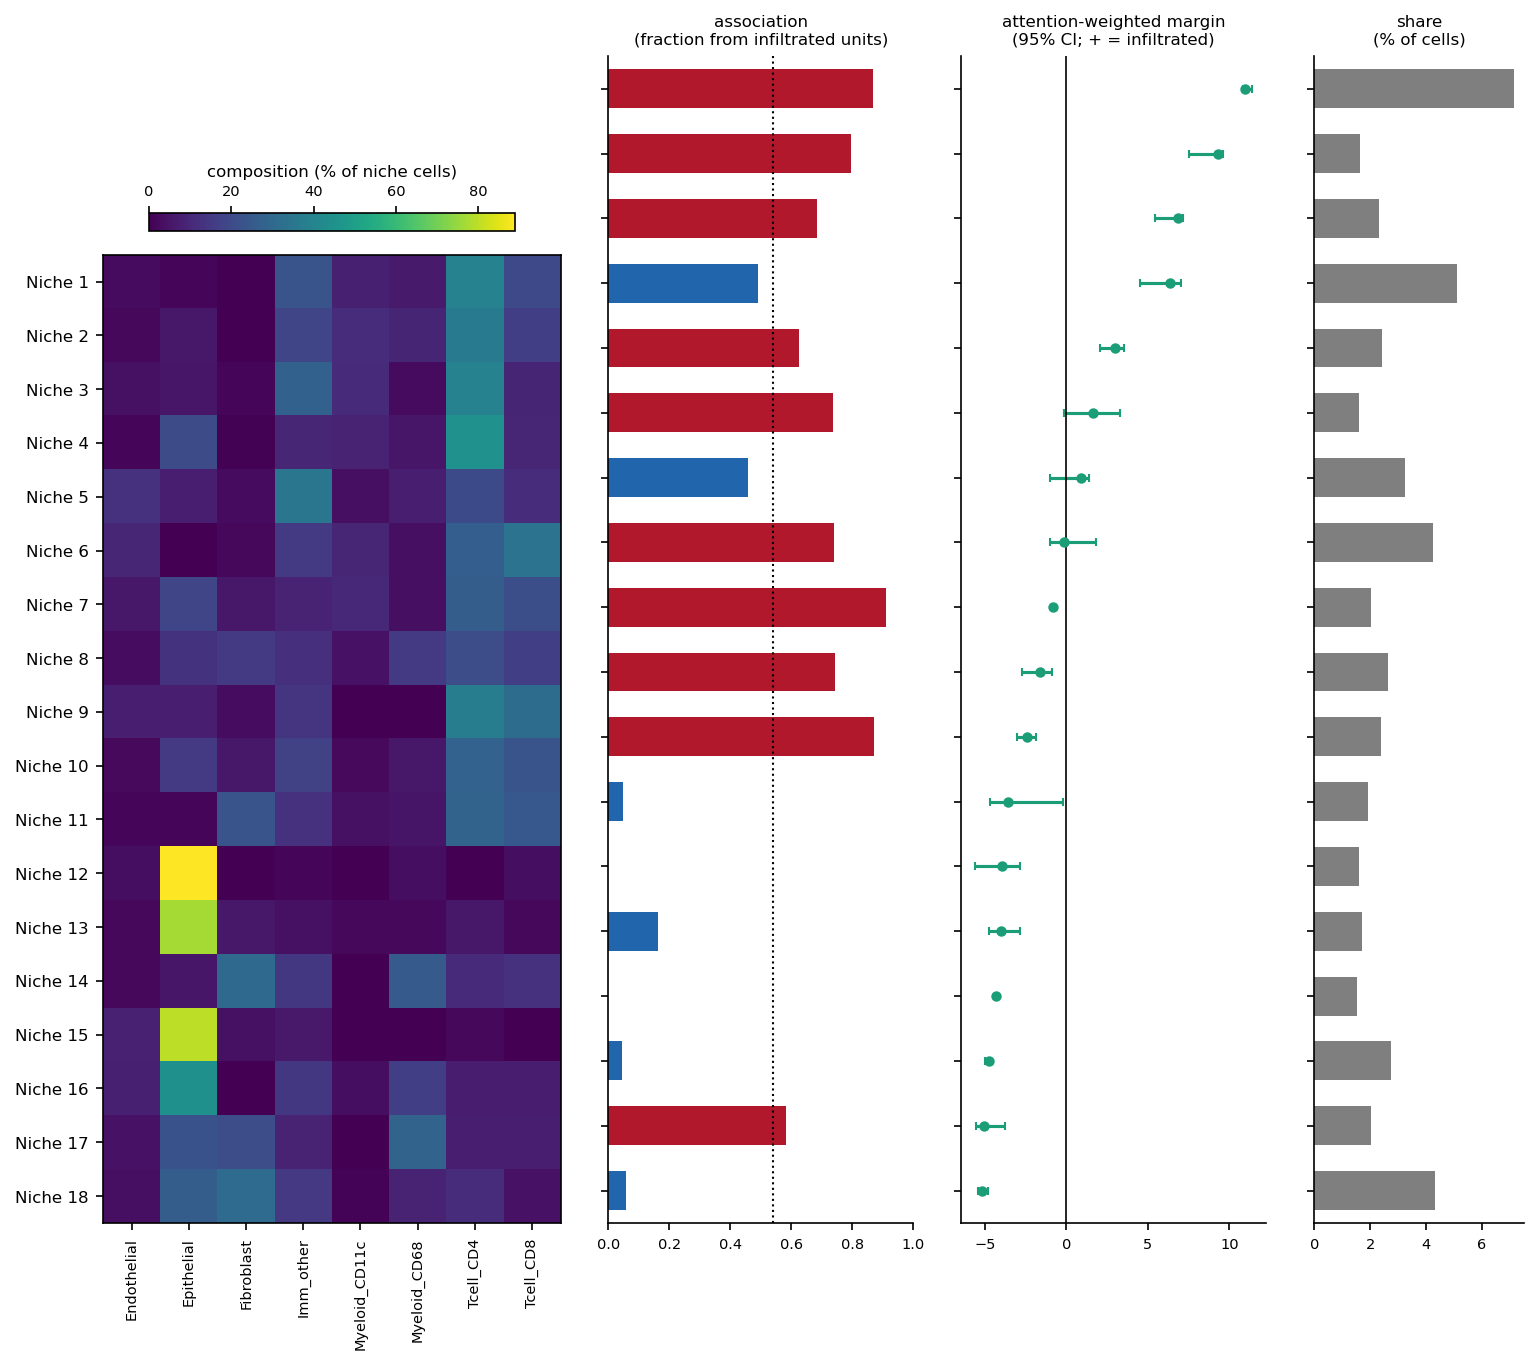

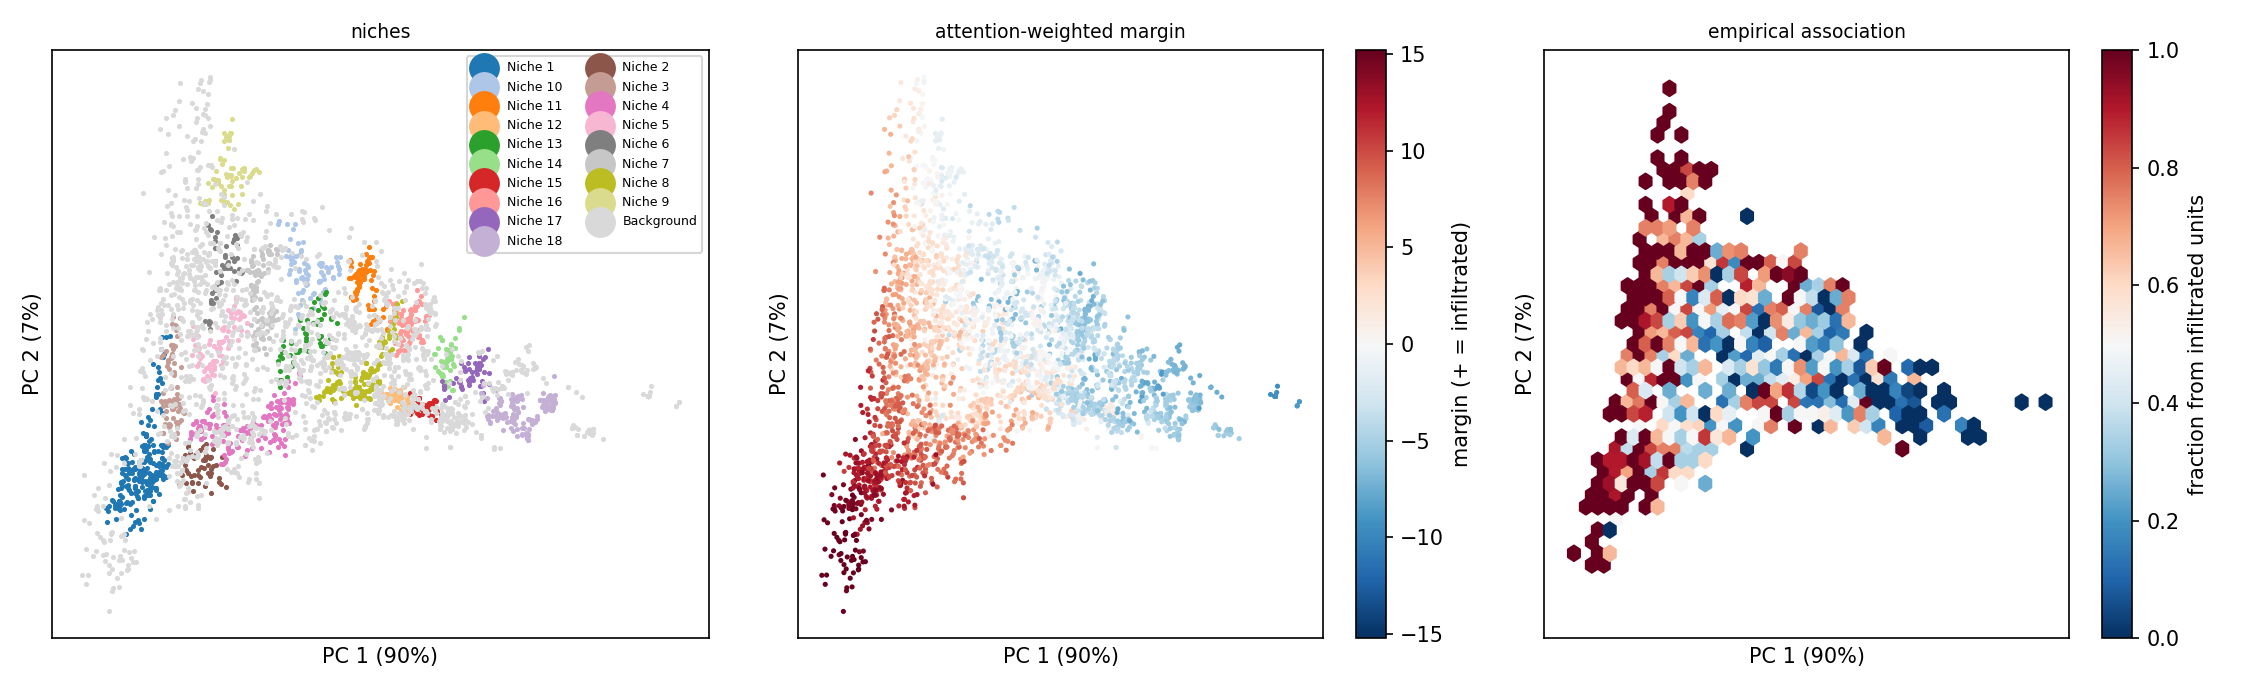

In [6]:
display(Image(NICHES / "figures" / "niche_panel.png"))
display(Image(NICHES / "figures" / "embedding.png"))

The niches the model weights most towards *infiltrated* (top) are T-cell rich
and come mostly from infiltrated tiles; epithelial and fibroblast niches sit at
the bottom. The maps show the most and least infiltrated
tiles as the model sees them: cell types, the margin of every cell and its niche.

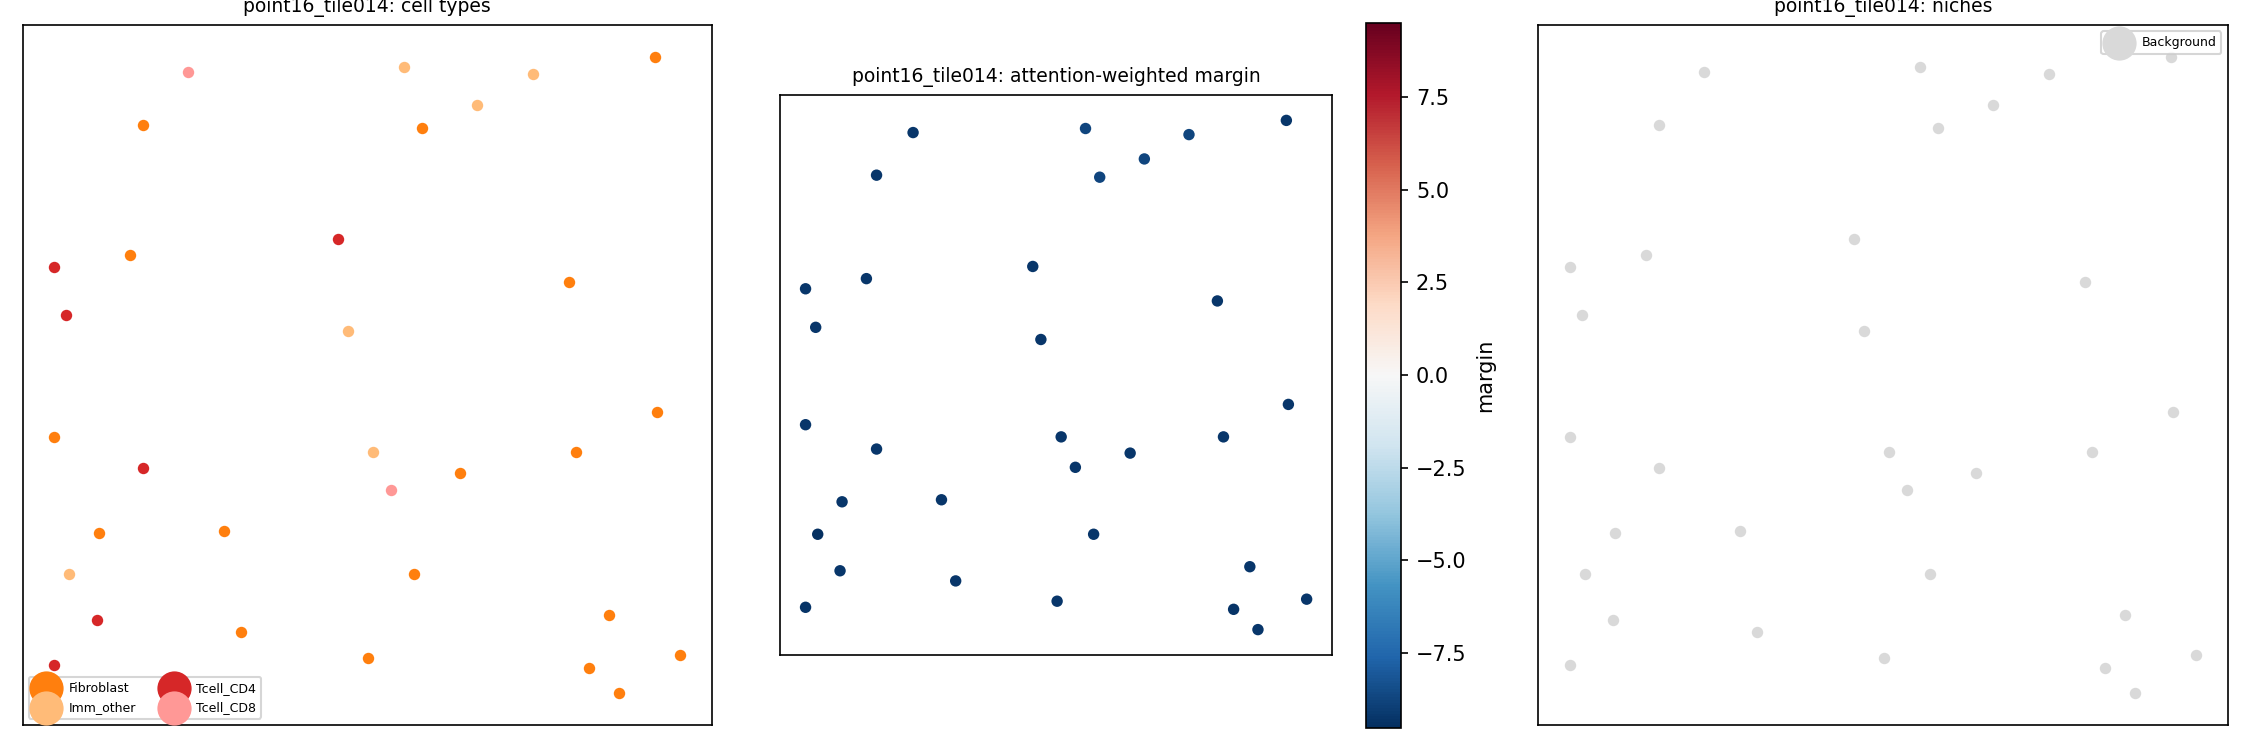

In [7]:
maps = sorted((NICHES / "figures" / "units").glob("*.png"))
display(Image(maps[0]))

Within every niche, classical statistics describe how its cells are arranged:
Moran's I of each cell type (tested against random labelling of the niche's
cells), neighbourhood enrichment and cross-L of every cell-type pair (relative to
random labelling, so the niche's own shape cancels), and contact enrichment
relative to the whole tissue.

,niche,cell_type,morans_i,expected,n_units,z,q
12,Niche 4,Epithelial,0.637,-0.032,2,6.514,0.000
57,Niche 12,Epithelial,0.444,-0.036,2,6.322,0.000
88,Niche 18,Epithelial,0.440,-0.020,1,5.590,0.000
26,Niche 7,Epithelial,0.615,-0.027,1,5.295,0.000
60,Niche 13,Epithelial,0.570,-0.031,1,5.032,0.000
75,Niche 16,Epithelial,0.298,-0.038,3,4.514,0.000
1,Niche 1,Imm_other,0.239,-0.031,4,4.369,0.000
40,Niche 9,Imm_other,0.399,-0.043,2,3.979,0.001


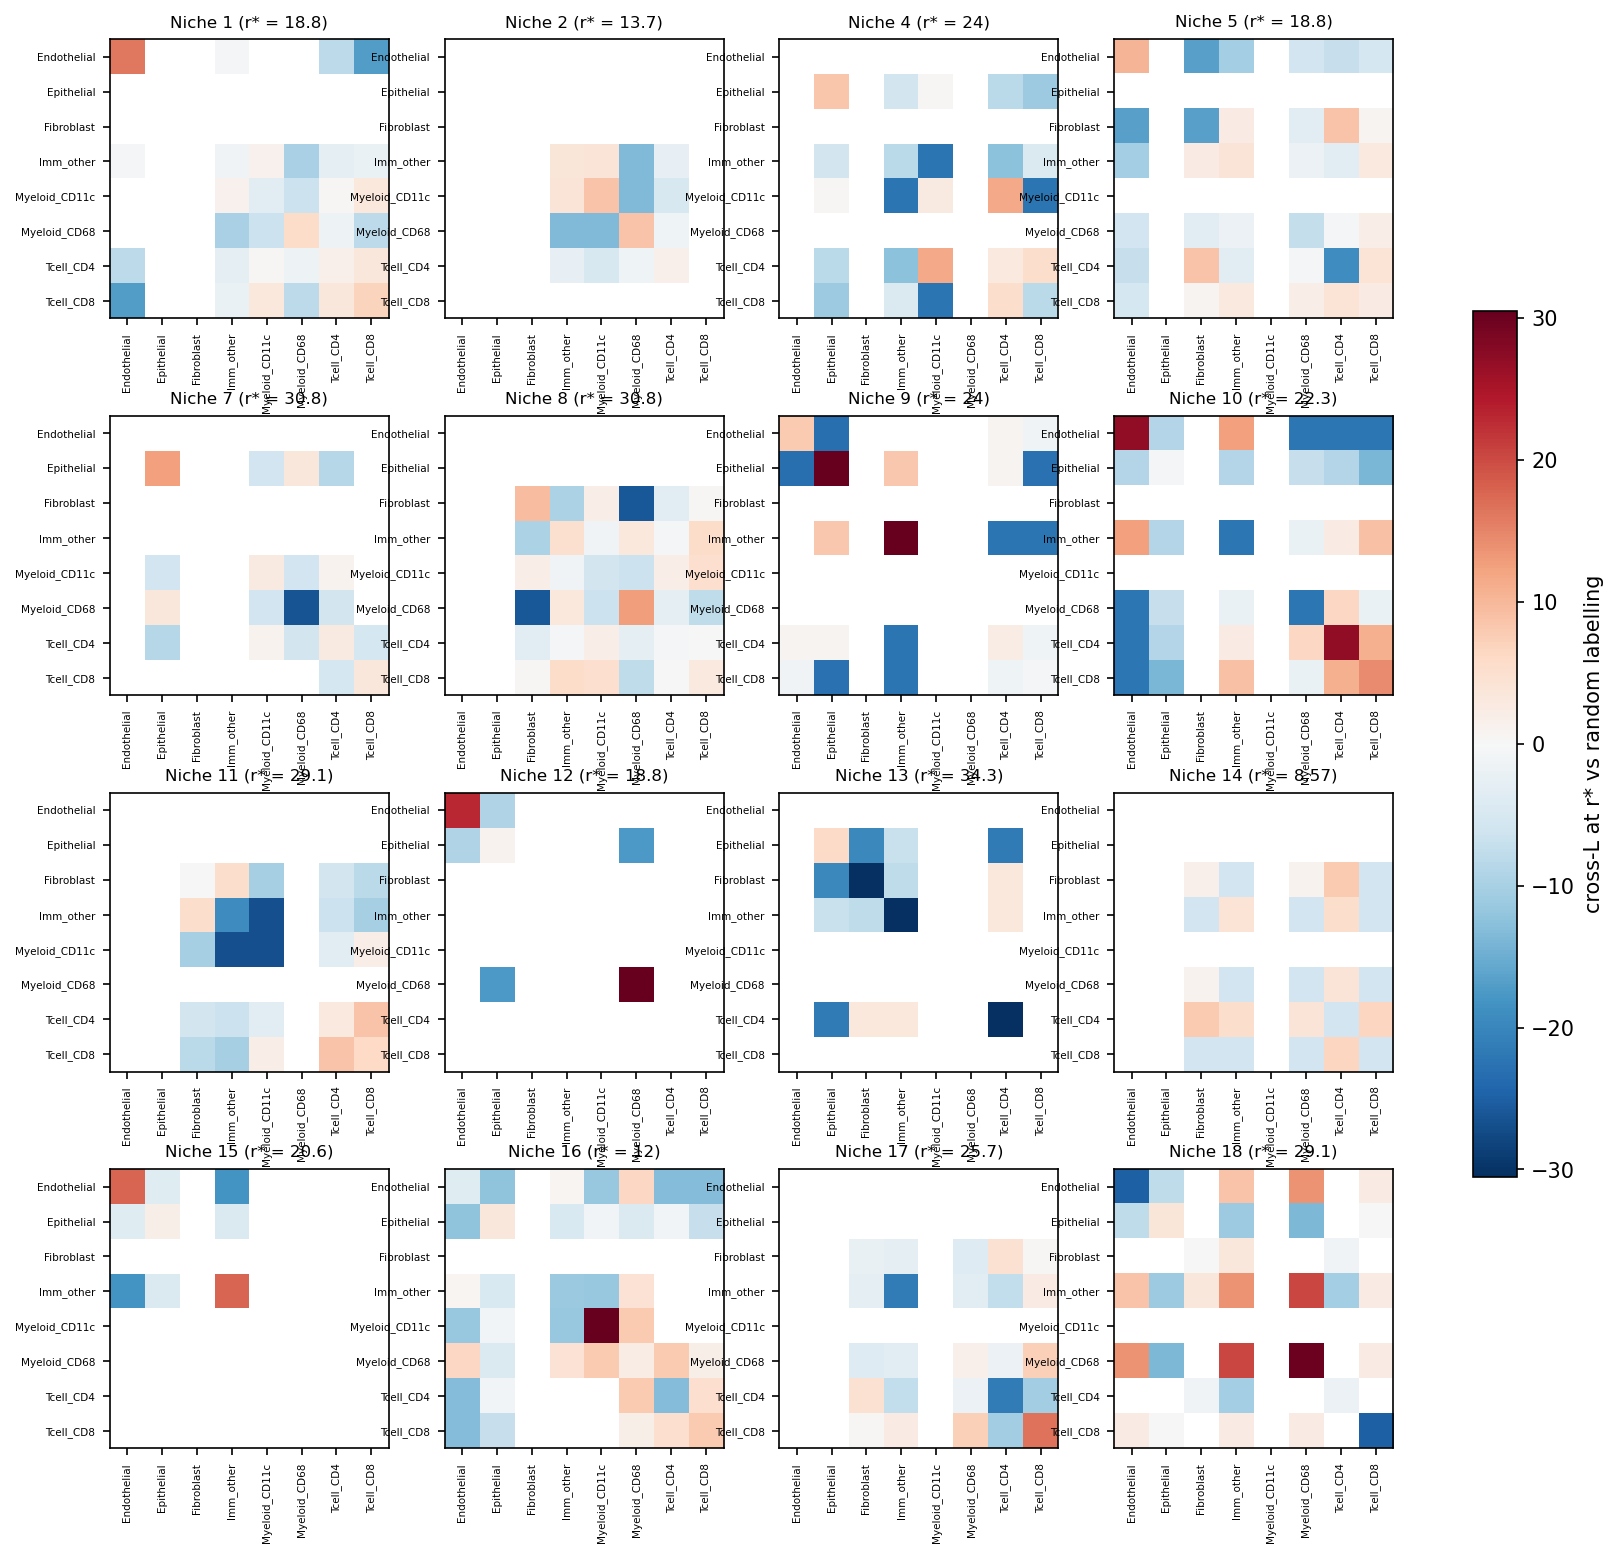

In [8]:
moran = pd.read_csv(NICHES / "descriptors" / "moran.csv")
columns = ["niche", "cell_type", "morans_i", "expected", "n_units", "z", "q"]
display(moran.sort_values("z", ascending=False)[columns].head(8).round(3))
display(Image(NICHES / "figures" / "cross_l.png"))